# Tugas Praktikum 4: Association Rule (Online Retail Dataset)
**Muhammad Fardan Hafidz - 5054251021**

---

### Deskripsi & Informasi Dataset
Dataset **Online Retail** (UCI Machine Learning Repository, didonasikan pada 11/5/2015 oleh Daqing Chen, Sai Laing Sain, dan Kun Guo, 2012) merupakan dataset transaksional yang memuat seluruh transaksi ritel *online* non-toko (*non-store online retail*) yang terdaftar di Inggris (*United Kingdom*) selama periode **01 Desember 2010 hingga 09 Desember 2011**. Perusahaan ini utamanya menjual produk hadiah unik untuk berbagai acara (*unique all-occasion gifts*), di mana sebagian besar pelanggannya merupakan pedagang grosir (*wholesalers*).

* **Karakteristik Dataset:** *Multivariate, Sequential, Time-Series*
* **Bidang Subjek:** *Business / Retail*
* **Jumlah Baris Awal:** 541.909 baris transaksi
* **Jumlah Atribut:** 8 kolom

| Nama Variabel | Peran (Role) | Tipe Data | Deskripsi Atribut | Satuan |
| :--- | :--- | :--- | :--- | :--- |
| **InvoiceNo** | ID | *Categorical (Nominal)* | Nomor unik 6 digit untuk setiap transaksi. Jika diawali huruf `'C'`, menandakan pembatalan (*cancellation*). | - |
| **StockCode** | ID | *Categorical (Nominal)* | Kode unik 5 digit untuk setiap produk/item yang berbeda. | - |
| **Description** | Feature | *Categorical (Nominal)* | Nama produk (*item name*). | - |
| **Quantity** | Feature | *Integer (Numeric)* | Kuantitas/jumlah setiap produk per transaksi. | Unit |
| **InvoiceDate** | Feature | *Date (Datetime)* | Tanggal dan waktu saat transaksi dibuat. | Waktu |
| **UnitPrice** | Feature | *Continuous (Numeric)* | Harga produk per unit dalam mata uang Poundsterling. | Sterling (£) |
| **CustomerID** | Feature | *Categorical (Nominal)* | Nomor unik 5 digit untuk setiap pelanggan. | - |
| **Country** | Feature | *Categorical (Nominal)* | Nama negara tempat tinggal pelanggan. | - |

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

### 1. Unduh dan Import Dataset
Pada tahap pertama, file dataset `Online Retail.xlsx` diimpor menggunakan `pd.read_excel()`, kemudian diperiksa struktur awalnya menggunakan `.head()`, `.shape`, dan `.info()`.

In [2]:
# Import dataset Online Retail.xlsx
start_load = time.time()
df = pd.read_excel('Online Retail.xlsx')
print(f"Dataset berhasil dimuat dalam {time.time() - start_load:.2f} detik.")
print(f"Dimensi Dataset (.shape): {df.shape[0]:,} baris x {df.shape[1]} kolom")

# Menampilkan 5 baris pertama dataset (.head())
display(df.head())

Dataset berhasil dimuat dalam 57.36 detik.
Dimensi Dataset (.shape): 541,909 baris x 8 kolom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
# Informasi struktur tipe data dan atribut (.info())
print("=== Informasi Struktur Dataset (.info()) ===")
df.info()

print("\n=== Ringkasan Statistik Numerik & Nilai Kosong ===")
summary_attr = pd.DataFrame({
    'Tipe Data': df.dtypes.astype(str),
    'Non-Null Count': df.notnull().sum(),
    'Missing Values (Null)': df.isnull().sum(),
    'Persentase Missing (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Jumlah Nilai Unik': df.nunique()
})
display(summary_attr)

=== Informasi Struktur Dataset (.info()) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

=== Ringkasan Statistik Numerik & Nilai Kosong ===


,Tipe Data,Non-Null Count,Missing Values (Null),Persentase Missing (%),Jumlah Nilai Unik
InvoiceNo,object,541909,0,0.00,25900
StockCode,object,541909,0,0.00,4070
Description,object,540455,1454,0.27,4223
Quantity,int64,541909,0,0.00,722
InvoiceDate,datetime64[ns],541909,0,0.00,23260
UnitPrice,float64,541909,0,0.00,1630
CustomerID,float64,406829,135080,24.93,4372
Country,object,541909,0,0.00,38


### 2. Eksplorasi dan Pembersihan Data (Data Cleaning)
Untuk analisis *Association Rule* berbasis keranjang belanja (*Market Basket Analysis*), kolom utama yang relevan adalah:
1. **`InvoiceNo`**: Sebagai pengenal unik (*transaction ID*) yang mengelompokkan item-item dalam satu transaksi pembelian.
2. **`Description`**: Sebagai nama produk/item yang dianalisis pola kemunculan bersamanya.
3. **`Quantity`**: Digunakan untuk memvalidasi bahwa item benar-benar dibeli dalam jumlah positif (`Quantity > 0`).

**Tahapan Pembersihan Data:**
* Menghapus baris dengan nilai `Description` kosong (`NaN` atau string kosong).
* Menghapus transaksi yang dibatalkan (*cancelled transactions*), yaitu baris dengan `InvoiceNo` yang diawali huruf **`"C"`**.
* Menghapus baris dengan nilai `Quantity` negatif atau nol (`Quantity <= 0`).
* Merapikan spasi berlebih pada teks `Description` menggunakan `.str.strip()` agar nama produk konsisten.

In [4]:
# Mencatat statistik sebelum pembersihan
rows_before = len(df)
invoices_before = df['InvoiceNo'].nunique()
products_before = df['Description'].nunique()

# Identifikasi rincian baris yang kotor/tidak valid
missing_desc_count = df['Description'].isnull().sum()
cancelled_count = df['InvoiceNo'].astype(str).str.upper().str.startswith('C').sum()
invalid_qty_count = (df['Quantity'] <= 0).sum()

print(f"Rincian Anomali pada Dataset Awal:")
print(f" - Baris dengan Description kosong (NaN)       : {missing_desc_count:,} baris")
print(f" - Transaksi dibatalkan (InvoiceNo diawali 'C'): {cancelled_count:,} baris")
print(f" - Baris dengan Quantity <= 0                  : {invalid_qty_count:,} baris")

# Proses pembersihan data (Data Cleaning)
df_clean = df.dropna(subset=['Description']).copy()
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str).str.strip()
df_clean = df_clean[~df_clean['InvoiceNo'].str.upper().str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean['Description'] = df_clean['Description'].astype(str).str.strip()
df_clean = df_clean[df_clean['Description'] != '']

# Mencatat statistik sesudah pembersihan
rows_after = len(df_clean)
invoices_after = df_clean['InvoiceNo'].nunique()
products_after = df_clean['Description'].nunique()

cleaning_summary = pd.DataFrame({
    'Metrik Dataset': ['Jumlah Baris Transaksi', 'Jumlah Invoice Unik (Transaksi)', 'Jumlah Produk Unik (Description)'],
    'Sebelum Pembersihan': [f"{rows_before:,}", f"{invoices_before:,}", f"{products_before:,}"],
    'Sesudah Pembersihan': [f"{rows_after:,}", f"{invoices_after:,}", f"{products_after:,}"],
    'Selisih (Dihapus)': [f"-{rows_before - rows_after:,} ({(rows_before - rows_after)/rows_before*100:.2f}%)",
                          f"-{invoices_before - invoices_after:,} ({(invoices_before - invoices_after)/invoices_before*100:.2f}%)",
                          f"-{products_before - products_after:,} ({(products_before - products_after)/products_before*100:.2f}%)"]
})

print("\n=== Perbandingan Dataset Sebelum dan Sesudah Pembersihan ===")
display(cleaning_summary)

Rincian Anomali pada Dataset Awal:
 - Baris dengan Description kosong (NaN)       : 1,454 baris
 - Transaksi dibatalkan (InvoiceNo diawali 'C'): 9,288 baris
 - Baris dengan Quantity <= 0                  : 10,624 baris

=== Perbandingan Dataset Sebelum dan Sesudah Pembersihan ===


,Metrik Dataset,Sebelum Pembersihan,Sesudah Pembersihan,Selisih (Dihapus)
0,Jumlah Baris Transaksi,"541,909","530,693","-11,216 (2.07%)"
1,Jumlah Invoice Unik (Transaksi),"25,900","20,136","-5,764 (22.25%)"
2,Jumlah Produk Unik (Description),"4,223","4,065",-158 (3.74%)


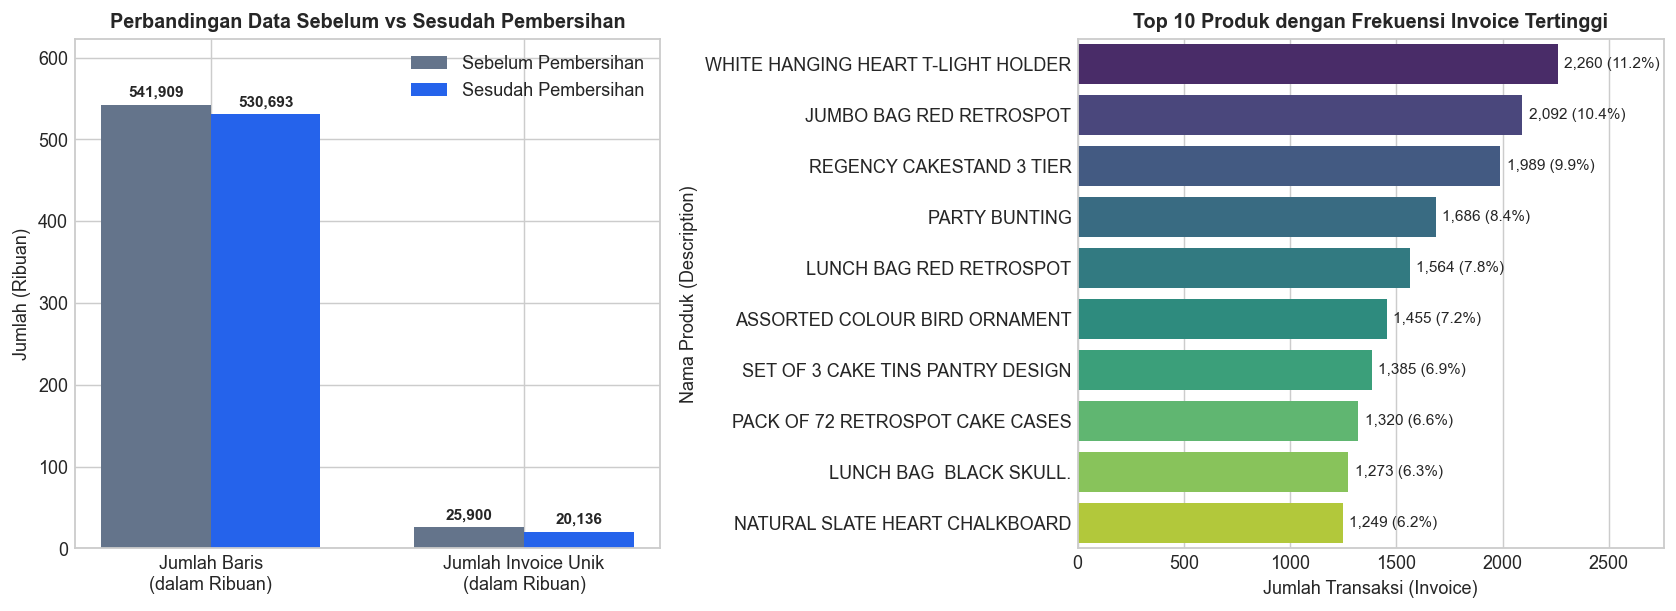

In [5]:
# Visualisasi Eksplorasi & Pembersihan Data
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Subplot 1: Perbandingan Sebelum vs Sesudah Pembersihan
categories = ['Jumlah Baris\n(dalam Ribuan)', 'Jumlah Invoice Unik\n(dalam Ribuan)']
before_vals = [rows_before / 1000, invoices_before / 1000]
after_vals = [rows_after / 1000, invoices_after / 1000]

x = np.arange(len(categories))
width = 0.35
rects1 = axes[0].bar(x - width/2, before_vals, width, label='Sebelum Pembersihan', color='#64748b')
rects2 = axes[0].bar(x + width/2, after_vals, width, label='Sesudah Pembersihan', color='#2563eb')
axes[0].set_title('Perbandingan Data Sebelum vs Sesudah Pembersihan', fontsize=11, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories)
axes[0].set_ylabel('Jumlah (Ribuan)')
axes[0].legend()
for rect, raw in zip(rects1, [rows_before, invoices_before]):
    axes[0].annotate(f'{raw:,}', xy=(rect.get_x() + rect.get_width()/2, rect.get_height()),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
for rect, raw in zip(rects2, [rows_after, invoices_after]):
    axes[0].annotate(f'{raw:,}', xy=(rect.get_x() + rect.get_width()/2, rect.get_height()),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')
axes[0].set_ylim(0, max(before_vals) * 1.15)

# Subplot 2: Top 10 Produk Paling Sering Muncul dalam Transaksi
top_items = df_clean.groupby('Description')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)
sns.barplot(x=top_items.values, y=top_items.index, ax=axes[1], palette='viridis', hue=top_items.index, legend=False)
axes[1].set_title('Top 10 Produk dengan Frekuensi Invoice Tertinggi', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Jumlah Transaksi (Invoice)')
axes[1].set_ylabel('Nama Produk (Description)')
for i, v in enumerate(top_items.values):
    axes[1].text(v + 30, i, f'{v:,} ({v/invoices_after*100:.1f}%)', va='center', fontsize=8.5)
axes[1].set_xlim(0, max(top_items.values) * 1.22)

plt.tight_layout()
plt.show()

### 3. Persiapan Data untuk Association Rule (One-Hot Basket Encoding)
Data transaksi yang telah bersih dikelompokkan berdasarkan `InvoiceNo`, di mana setiap transaksi merepresentasikan satu keranjang belanja (*basket*) berisi daftar produk (`Description`) yang dibeli. Selanjutnya, daftar transaksi tersebut ditransformasikan ke dalam matriks *one-hot encoding* (`True`/`False`) menggunakan `TransactionEncoder` dari pustaka `mlxtend`.

In [6]:
# Mengelompokkan produk berdasarkan InvoiceNo menjadi list transaksi
start_basket = time.time()
transactions_by_invoice = df_clean.groupby('InvoiceNo')['Description'].apply(lambda items: sorted(list(set(items))))
transactions_list = transactions_by_invoice.tolist()

print(f"Contoh 3 transaksi pertama (berbasis InvoiceNo):")
for inv_no, items in list(transactions_by_invoice.items())[:3]:
    print(f" - Invoice {inv_no} ({len(items)} item): {items[:5]}{' ...' if len(items) > 5 else ''}")

# Mengubah daftar transaksi ke bentuk One-Hot Encoded DataFrame (Basket)
te = TransactionEncoder()
te_array = te.fit(transactions_list).transform(transactions_list)
basket_df = pd.DataFrame(te_array, columns=te.columns_, index=transactions_by_invoice.index)

print(f"\nTransformasi One-Hot Basket selesai dalam {time.time() - start_basket:.2f} detik.")
print(f"Dimensi Matriks One-Hot Basket: {basket_df.shape[0]:,} invoice x {basket_df.shape[1]:,} produk unik")
display(basket_df.iloc[:5, :8])

Contoh 3 transaksi pertama (berbasis InvoiceNo):
 - Invoice 536365 (7 item): ['CREAM CUPID HEARTS COAT HANGER', 'GLASS STAR FROSTED T-LIGHT HOLDER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES'] ...
 - Invoice 536366 (2 item): ['HAND WARMER RED POLKA DOT', 'HAND WARMER UNION JACK']
 - Invoice 536367 (12 item): ['ASSORTED COLOUR BIRD ORNAMENT', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE ALPHABET BLOCKS', 'BOX OF VINTAGE JIGSAW BLOCKS', 'DOORMAT NEW ENGLAND'] ...

Transformasi One-Hot Basket selesai dalam 0.64 detik.
Dimensi Matriks One-Hot Basket: 20,136 invoice x 4,065 produk unik


,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False


### 4. Penerapan Algoritma (FP-Growth & Apriori) dan Penyesuaian Parameter
Pada tahap ini, algoritma **FP-Growth** dan **Apriori** diterapkan untuk mengekstraksi *frequent itemsets* dan aturan asosiasi:
1. **Titik Awal (`min_support = 0.01`, `min_confidence = 0.5`)**:
   * Ditemukan **1.853 *frequent itemsets*** dan **841 aturan asosiasi**.
   * **Analisis Jumlah Aturan pada Titik Awal**: Jumlah 841 aturan relatif **terlalu banyak** untuk dieksekusi langsung oleh tim pemasaran ritel karena didominasi oleh kombinasi permutasi 3–4 item dari produk musiman/spesifik (seperti *Herb Marker* yang hanya dibeli pada ~1% transaksi oleh pedagang grosir tertentu).
2. **Penyesuaian Parameter (`min_support` dan `min_confidence`)**:
   * Untuk menyaring aturan yang lebih berdampak luas (*high-volume retail items*) dan mengurangi redundansi aturan, dilakukan eksperimen peningkatan nilai ambang menjadi `min_support = 0.015` hingga `0.02` serta `min_confidence = 0.6`.
   * Pada **`min_support = 0.02` dan `min_confidence = 0.6`**, jumlah *frequent itemsets* menyusut menjadi **376 itemsets** dan menghasilkan **31 aturan asosiasi utama** yang sangat kuat, stabil, dan mewakili produk terlaris toko (seperti *Regency Teacup & Saucer*, *Lunch Bag*, *Jumbo Bag*, dan *Alarm Clock*).

In [7]:
# 4.1 Penerapan Algoritma FP-Growth & Apriori pada Titik Awal (min_support = 0.01, min_confidence = 0.5)
t0 = time.time()
freq_itemsets_fp_001 = fpgrowth(basket_df, min_support=0.01, use_colnames=True)
fp_time = time.time() - t0

t1 = time.time()
freq_itemsets_ap_001 = apriori(basket_df, min_support=0.01, use_colnames=True, low_memory=True)
ap_time = time.time() - t1

rules_initial = association_rules(freq_itemsets_fp_001, metric="confidence", min_threshold=0.5)
rules_initial['antecedent_len'] = rules_initial['antecedents'].apply(len)
rules_initial['consequent_len'] = rules_initial['consequents'].apply(len)

print(f"Perbandingan Algoritma pada min_support = 0.01:")
print(f" - FP-Growth : {len(freq_itemsets_fp_001):,} frequent itemsets ditemukan dalam {fp_time:.2f} detik")
print(f" - Apriori   : {len(freq_itemsets_ap_001):,} frequent itemsets ditemukan dalam {ap_time:.2f} detik")
print(f" - Jumlah Aturan Asosiasi (min_confidence = 0.5): {len(rules_initial):,} aturan")

# Menampilkan 10 Frequent Itemsets dengan Support tertinggi
freq_itemsets_fp_001['length'] = freq_itemsets_fp_001['itemsets'].apply(len)
print("\nTop 10 Frequent Itemsets (Berdasarkan Support):")
display(freq_itemsets_fp_001.sort_values(by='support', ascending=False).head(10))

Perbandingan Algoritma pada min_support = 0.01:
 - FP-Growth : 1,853 frequent itemsets ditemukan dalam 4.68 detik
 - Apriori   : 1,853 frequent itemsets ditemukan dalam 1.39 detik
 - Jumlah Aturan Asosiasi (min_confidence = 0.5): 841 aturan

Top 10 Frequent Itemsets (Berdasarkan Support):


,support,itemsets,length
0,0.112237,WHITE HANGING HEART T-LIGHT HOLDER,1
1,0.103894,JUMBO BAG RED RETROSPOT,1
2,0.098778,REGENCY CAKESTAND 3 TIER,1
3,0.083731,PARTY BUNTING,1
4,0.077672,LUNCH BAG RED RETROSPOT,1
5,0.072259,ASSORTED COLOUR BIRD ORNAMENT,1
6,0.068782,SET OF 3 CAKE TINS PANTRY DESIGN,1
7,0.065554,PACK OF 72 RETROSPOT CAKE CASES,1
8,0.063220,LUNCH BAG BLACK SKULL.,1
9,0.062028,NATURAL SLATE HEART CHALKBOARD,1


In [8]:
# 4.2 Eksperimen Penyesuaian Nilai Minimum Support dan Minimum Confidence
param_configs = [
    (0.010, 0.50, "Titik Awal (Sangat Sensitif / Banyak Aturan)"),
    (0.010, 0.60, "Support Rendah, Confidence Ketat"),
    (0.010, 0.70, "Support Rendah, Confidence Sangat Ketat"),
    (0.015, 0.50, "Support Menengah, Confidence Standar"),
    (0.015, 0.60, "Support Menengah, Confidence Ketat (Seimbang)"),
    (0.020, 0.50, "Support Tinggi, Confidence Standar"),
    (0.020, 0.60, "Parameter Terfokus (Optimal untuk Produk Utama)")
]

tuning_rows = []
cached_freq = {}
for sup, conf, desc in param_configs:
    if sup not in cached_freq:
        cached_freq[sup] = fpgrowth(basket_df, min_support=sup, use_colnames=True)
    f_df = cached_freq[sup]
    r_df = association_rules(f_df, metric="confidence", min_threshold=conf)
    tuning_rows.append({
        'Min Support': sup,
        'Min Confidence': conf,
        'Jumlah Frequent Itemset': len(f_df),
        'Jumlah Aturan (Rules)': len(r_df),
        'Rata-rata Lift': round(r_df['lift'].mean(), 2) if len(r_df) > 0 else 0,
        'Maksimum Lift': round(r_df['lift'].max(), 2) if len(r_df) > 0 else 0,
        'Keterangan Konfigurasi': desc
    })

tuning_df = pd.DataFrame(tuning_rows)
print("=== Tabel Eksperimen Penyesuaian Parameter Support & Confidence ===")
display(tuning_df)

# Menyimpan aturan terfokus (min_support = 0.02, min_confidence = 0.6)
rules_tuned = association_rules(cached_freq[0.020], metric="confidence", min_threshold=0.60)
rules_tuned = rules_tuned.sort_values(by=['lift', 'confidence'], ascending=False).reset_index(drop=True)

=== Tabel Eksperimen Penyesuaian Parameter Support & Confidence ===


,Min Support,Min Confidence,Jumlah Frequent Itemset,Jumlah Aturan (Rules),Rata-rata Lift,Maksimum Lift,Keterangan Konfigurasi
0,0.010,0.5,1853,841,17.53,80.22,Titik Awal (Sangat Sensitif / Banyak Aturan)
1,0.010,0.6,1853,498,20.02,80.22,"Support Rendah, Confidence Ketat"
2,0.010,0.7,1853,260,23.28,80.22,"Support Rendah, Confidence Sangat Ketat"
3,0.015,0.5,695,177,12.89,37.89,"Support Menengah, Confidence Standar"
4,0.015,0.6,695,94,15.11,37.89,"Support Menengah, Confidence Ketat (Seimbang)"
5,0.020,0.5,376,61,10.99,18.55,"Support Tinggi, Confidence Standar"
6,0.020,0.6,376,31,12.01,18.55,Parameter Terfokus (Optimal untuk Produk Utama)


### 5. Evaluasi Aturan Asosiasi & Interpretasi Tiga Aturan Terbaik
Evaluasi aturan asosiasi dilakukan menggunakan tiga metrik utama:
* **Support**: Proporsi transaksi di seluruh dataset yang memuat item *antecedent* ($A$) dan *consequent* ($B$) secara bersamaan: $P(A \cap B)$.
* **Confidence**: Probabilitas bersyarat pelanggan membeli item $B$ jika diketahui telah membeli item $A$: $P(B|A) = \frac{Support(A \cup B)}{Support(A)}$.
* **Lift**: Rasio peningkatan peluang pembelian item $B$ ketika item $A$ dibeli dibandingkan jika kedua item dibeli secara independen: $Lift(A \rightarrow B) = \frac{Confidence(A \rightarrow B)}{Support(B)}$. Nilai **Lift > 1** menunjukkan asosiasi positif yang kuat.

In [9]:
# Format tampilan aturan agar mudah dibaca
def format_rules_table(df_rules, top_n=15):
    out = df_rules.sort_values(by=['lift', 'confidence', 'support'], ascending=False).head(top_n).copy()
    out['Antecedents (Jika Membeli)'] = out['antecedents'].apply(lambda s: ', '.join(sorted(list(s))))
    out['Consequents (Maka Membeli)'] = out['consequents'].apply(lambda s: ', '.join(sorted(list(s))))
    cols = ['Antecedents (Jika Membeli)', 'Consequents (Maka Membeli)', 'support', 'confidence', 'lift', 'leverage', 'conviction']
    res = out[cols].reset_index(drop=True)
    for c in ['support', 'confidence', 'lift', 'leverage', 'conviction']:
        res[c] = res[c].round(4)
    return res

print("=== Top 15 Aturan Asosiasi Berdasarkan Lift (Titik Awal: min_support = 0.01, min_confidence = 0.5) ===")
top15_initial = format_rules_table(rules_initial, 15)
display(top15_initial)

print("\n=== Top 15 Aturan Asosiasi Berdasarkan Lift (Hasil Penyesuaian: min_support = 0.02, min_confidence = 0.6) ===")
top15_tuned = format_rules_table(rules_tuned, 15)
display(top15_tuned)

=== Top 15 Aturan Asosiasi Berdasarkan Lift (Titik Awal: min_support = 0.01, min_confidence = 0.5) ===


,Antecedents (Jika Membeli),Consequents (Maka Membeli),support,confidence,lift,leverage,conviction
0,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",HERB MARKER THYME,0.0101,0.9442,80.2200,0.0100,17.7058
1,HERB MARKER THYME,"HERB MARKER PARSLEY, HERB MARKER ROSEMARY",0.0101,0.8565,80.2200,0.0100,6.8962
2,HERB MARKER ROSEMARY,"HERB MARKER PARSLEY, HERB MARKER THYME",0.0101,0.8458,79.9610,0.0100,6.4179
3,"HERB MARKER PARSLEY, HERB MARKER THYME",HERB MARKER ROSEMARY,0.0101,0.9531,79.9610,0.0100,21.0461
4,HERB MARKER THYME,HERB MARKER ROSEMARY,0.0110,0.9325,78.2359,0.0108,14.6360
5,HERB MARKER ROSEMARY,HERB MARKER THYME,0.0110,0.9208,78.2359,0.0108,12.4829
6,"HERB MARKER ROSEMARY, HERB MARKER THYME",HERB MARKER PARSLEY,0.0101,0.9186,77.7141,0.0100,12.1327
7,HERB MARKER PARSLEY,"HERB MARKER ROSEMARY, HERB MARKER THYME",0.0101,0.8529,77.7141,0.0100,6.7254
8,HERB MARKER THYME,HERB MARKER PARSLEY,0.0106,0.8987,76.0374,0.0104,9.7583
9,HERB MARKER PARSLEY,HERB MARKER THYME,0.0106,0.8950,76.0374,0.0104,9.4079



=== Top 15 Aturan Asosiasi Berdasarkan Lift (Hasil Penyesuaian: min_support = 0.02, min_confidence = 0.6) ===


,Antecedents (Jika Membeli),Consequents (Maka Membeli),support,confidence,lift,leverage,conviction
0,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.0269,0.7076,18.5516,0.0255,3.2892
1,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",PINK REGENCY TEACUP AND SAUCER,0.0269,0.7057,18.5516,0.0255,3.2690
2,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",GREEN REGENCY TEACUP AND SAUCER,0.0269,0.9048,17.9506,0.0254,9.9791
3,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.0314,0.8264,16.3939,0.0295,5.4691
4,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.0314,0.6236,16.3939,0.0295,2.5560
5,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY TEACUP AND SAUCER",ROSES REGENCY TEACUP AND SAUCER,0.0269,0.8562,16.1738,0.0253,6.5878
6,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.0271,0.7203,15.8864,0.0254,3.4134
7,"REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAUCER",GREEN REGENCY TEACUP AND SAUCER,0.0203,0.7771,15.4173,0.0189,4.2610
8,"GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER",ROSES REGENCY TEACUP AND SAUCER,0.0203,0.8016,15.1411,0.0189,4.7728
9,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.0297,0.7820,14.7711,0.0277,4.3440


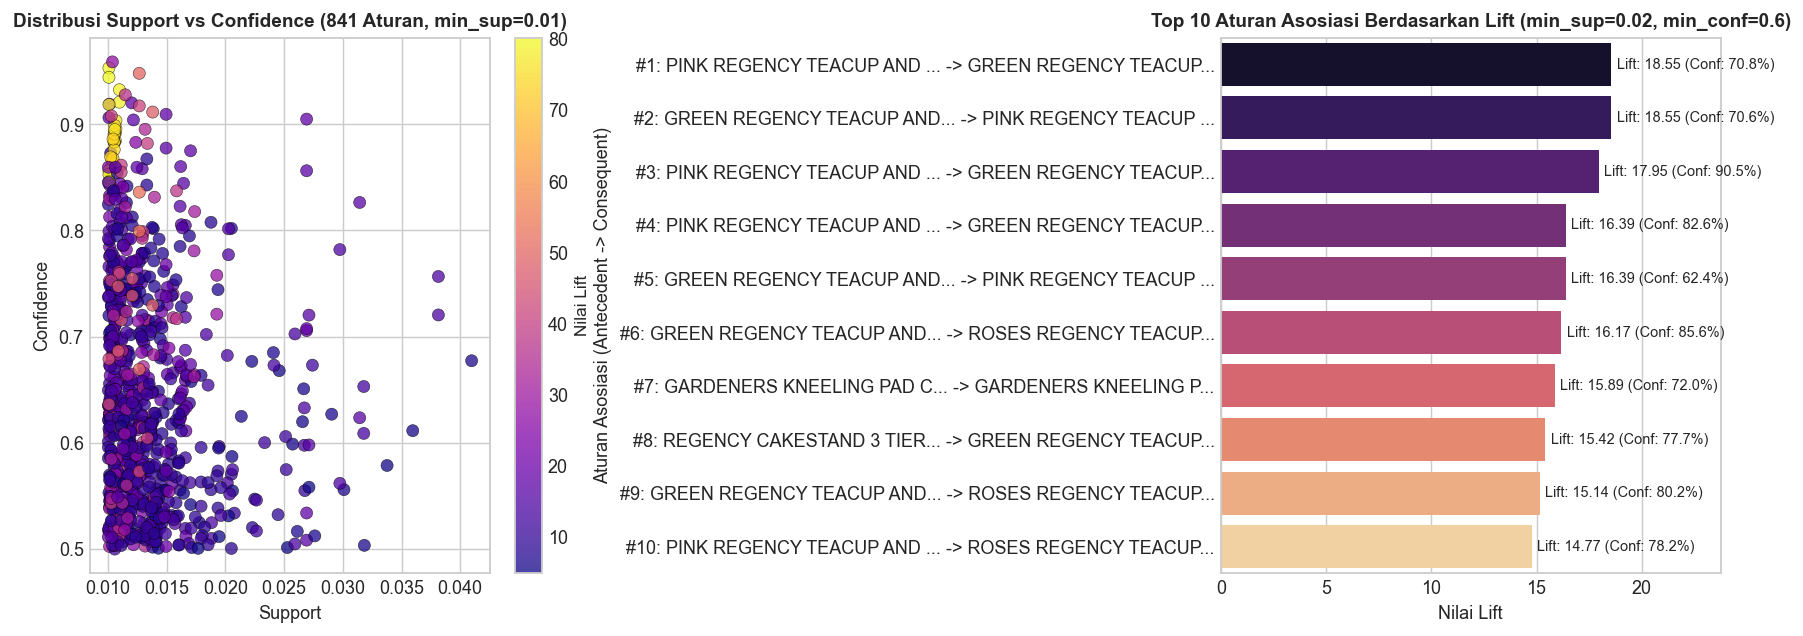

In [10]:
# Visualisasi Evaluasi Aturan Asosiasi
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Subplot 1: Scatter Plot Support vs Confidence (Titik Awal min_sup=0.01, min_conf=0.5)
sc = axes[0].scatter(rules_initial['support'], rules_initial['confidence'],
                     c=rules_initial['lift'], cmap='plasma', alpha=0.75, s=45, edgecolors='k', linewidth=0.3)
cbar = plt.colorbar(sc, ax=axes[0])
cbar.set_label('Nilai Lift', fontsize=9.5)
axes[0].set_title('Distribusi Support vs Confidence (841 Aturan, min_sup=0.01)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Support')
axes[0].set_ylabel('Confidence')

# Subplot 2: Top 10 Aturan Terbaik pada Parameter Terfokus (min_sup=0.02, min_conf=0.6) berdasarkan Lift
top10_plot = top15_tuned.head(10).copy()
top10_plot['Rule_Label'] = [
    f"#{i+1}: {r['Antecedents (Jika Membeli)'][:24]}... -> {r['Consequents (Maka Membeli)'][:20]}..."
    for i, (_, r) in enumerate(top10_plot.iterrows())
]
sns.barplot(data=top10_plot, x='lift', y='Rule_Label', palette='magma', ax=axes[1], hue='Rule_Label', legend=False)
axes[1].set_title('Top 10 Aturan Asosiasi Berdasarkan Lift (min_sup=0.02, min_conf=0.6)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Nilai Lift')
axes[1].set_ylabel('Aturan Asosiasi (Antecedent -> Consequent)')
for i, (lft, cnf) in enumerate(zip(top10_plot['lift'], top10_plot['confidence'])):
    axes[1].text(lft + 0.25, i, f'Lift: {lft:.2f} (Conf: {cnf*100:.1f}%)', va='center', fontsize=8)
axes[1].set_xlim(0, top10_plot['lift'].max() * 1.28)

plt.tight_layout()
plt.show()

In [11]:
# Menampilkan Tiga Aturan Terbaik Berdasarkan Nilai Lift
print("=========================================================================================")
print("A. TIGA ATURAN TERBAIK PADA TITIK AWAL (min_support = 0.01, min_confidence = 0.5)")
print("=========================================================================================")
for i, row in top15_initial.head(3).iterrows():
    print(f"Aturan #{i+1}: [{row['Antecedents (Jika Membeli)']}] ==> [{row['Consequents (Maka Membeli)']}]")
    print(f"   - Support    : {row['support']:.4f} ({row['support']*100:.2f}% dari total 20.136 transaksi)")
    print(f"   - Confidence : {row['confidence']:.4f} ({row['confidence']*100:.2f}% peluang dibeli bersamaan)")
    print(f"   - Lift       : {row['lift']:.4f}x peningkatan peluang pembelian\n")

print("=========================================================================================")
print("B. TIGA ATURAN TERBAIK PADA PARAMETER TERFOKUS (min_support = 0.02, min_confidence = 0.6)")
print("   (Mewakili 3 Kelompok Produk Utama Berbeda dengan Lift Tertinggi)")
print("=========================================================================================")
selected_indices = [0, 6, 8]
for rank, idx in enumerate(selected_indices, 1):
    row = top15_tuned.loc[idx]
    print(f"Aturan Utama #{rank}: [{row['Antecedents (Jika Membeli)']}] ==> [{row['Consequents (Maka Membeli)']}]")
    print(f"   - Support    : {row['support']:.4f} ({row['support']*100:.2f}% dari total 20.136 transaksi)")
    print(f"   - Confidence : {row['confidence']:.4f} ({row['confidence']*100:.2f}% peluang dibeli bersamaan)")
    print(f"   - Lift       : {row['lift']:.4f}x peningkatan peluang pembelian\n")

A. TIGA ATURAN TERBAIK PADA TITIK AWAL (min_support = 0.01, min_confidence = 0.5)
Aturan #1: [HERB MARKER PARSLEY, HERB MARKER ROSEMARY] ==> [HERB MARKER THYME]
   - Support    : 0.0101 (1.01% dari total 20.136 transaksi)
   - Confidence : 0.9442 (94.42% peluang dibeli bersamaan)
   - Lift       : 80.2200x peningkatan peluang pembelian

Aturan #2: [HERB MARKER THYME] ==> [HERB MARKER PARSLEY, HERB MARKER ROSEMARY]
   - Support    : 0.0101 (1.01% dari total 20.136 transaksi)
   - Confidence : 0.8565 (85.65% peluang dibeli bersamaan)
   - Lift       : 80.2200x peningkatan peluang pembelian

Aturan #3: [HERB MARKER ROSEMARY] ==> [HERB MARKER PARSLEY, HERB MARKER THYME]
   - Support    : 0.0101 (1.01% dari total 20.136 transaksi)
   - Confidence : 0.8458 (84.58% peluang dibeli bersamaan)
   - Lift       : 79.9610x peningkatan peluang pembelian

B. TIGA ATURAN TERBAIK PADA PARAMETER TERFOKUS (min_support = 0.02, min_confidence = 0.6)
   (Mewakili 3 Kelompok Produk Utama Berbeda dengan Lift 

### 6. Penyusunan Laporan & Analisis Konteks Bisnis Ritel

#### 6.1 Ringkasan Hasil Eksplorasi dan Pembersihan Data
* Dataset awal `Online Retail.xlsx` memiliki **541.909 baris** dan **25.900 nomor invoice unik** dengan 8 kolom atribut.
* Ditemukan tiga sumber utama ketidakbersihan data (*noise*) yang dapat mendistorsi perhitungan *support* dan *confidence*:
  1. **1.454 baris** tidak memiliki nama produk (`Description` bernilai `NaN`).
  2. **9.288 baris** merupakan transaksi pembatalan pesanan (`InvoiceNo` diawali huruf `'C'`).
  3. **10.624 baris** memiliki kuantitas tidak valid (`Quantity <= 0`, mencakup transaksi retur/batal dan koreksi gudang).
* Setelah pembersihan data dilakukan, diperoleh **530.693 baris transaksi bersih** yang tergabung ke dalam **20.136 invoice unik** dan **4.065 produk unik**. Sebanyak **90,36%** transaksi berasal dari pelanggan di Inggris (*United Kingdom*).

#### 6.2 Analisis Penerapan Algoritma & Penyesuaian Parameter
* Baik algoritma **FP-Growth** maupun **Apriori** menghasilkan jumlah *frequent itemsets* yang sama persis, yaitu **1.853 itemsets** pada `min_support = 0.01` (waktu eksekusi Apriori: 1,39 detik; FP-Growth: 4,68 detik).
* Pada parameter awal (`min_support = 0.01`, `min_confidence = 0.5`), terbentuk **841 aturan asosiasi** (rata-rata Lift **17,53**, maksimum Lift **80,22**). Karena jumlah 841 aturan terlalu besar dan banyak memuat kombinasi berulang dari item berfrekuensi ~1%, dilakukan penyesuaian parameter ke **`min_support = 0.02`** dan **`min_confidence = 0.6`** yang menyaring aturan menjadi **31 aturan inti** dengan rata-rata Lift **12,01** dan cakupan transaksi minimal 2% (~403 invoice per aturan).

#### 6.3 Interpretasi Tiga Aturan Terbaik Berdasarkan Nilai Lift dalam Konteks Bisnis Ritel

1. **Aturan 1 — Pola Pembelian Koleksi Penanda Tanaman (*Herb Marker Series*) & Set Cangkir (*Regency Teacup Trio*):**
   * **Pada `min_support = 0.01`**: `{HERB MARKER PARSLEY, HERB MARKER ROSEMARY} -> {HERB MARKER THYME}` (**Support = 1,01%**, **Confidence = 94,42%**, **Lift = 80,22**) serta `{HERB MARKER THYME} -> {HERB MARKER PARSLEY, HERB MARKER ROSEMARY}` (**Support = 1,01%**, **Confidence = 85,65%**, **Lift = 80,22**).
   * **Pada `min_support = 0.02`**: `{PINK REGENCY TEACUP AND SAUCER} -> {GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER}` (**Support = 2,69%**, **Confidence = 70,76%**, **Lift = 18,55**) serta `{PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER} -> {GREEN REGENCY TEACUP AND SAUCER}` (**Support = 2,69%**, **Confidence = 90,48%**, **Lift = 17,95**).
   * **Interpretasi Bisnis Ritel:** Nilai Lift **80,22** (dan **18,55** pada koleksi cangkir *Regency*) menunjukkan bahwa pelanggan (khususnya pembeli grosir/*wholesaler* dan toko suvenir) hampir tidak pernah membeli satu varian warna/jenis saja, melainkan membeli **satu seri lengkap (*complete set*)** untuk dipajang bersama di etalase toko mereka. Perusahaan ritel sebaiknya menyediakan paket *bundling* ("Full Set Herb Markers" atau "Regency Trio Teacup Bundle") dengan harga paket khusus.

2. **Aturan 2 — Pola Pembelian Perlengkapan Taman & Dekorasi (*Gardeners Kneeling Pad Series*):**
   * **Aturan**: `{GARDENERS KNEELING PAD CUP OF TEA} -> {GARDENERS KNEELING PAD KEEP CALM}` (**Support = 2,71%**, **Confidence = 72,03%**, **Lift = 15,89**).
   * **Interpretasi Bisnis Ritel:** Sebanyak 72,03% pelanggan yang membeli alas lutut berkebun bermotif *Cup of Tea* juga membeli motif *Keep Calm* (muncul bersama di 546 invoice), dengan peluang 15,89 kali lipat lebih tinggi dibandingkan pelanggan acak. Dalam konteks *e-commerce*, fitur rekomendasi otomatis (*"Frequently Bought Together"*) pada halaman produk wajib menampilkan kedua desain slogan tersebut secara berdampingan.

3. **Aturan 3 — Pola Pembelian Pelengkap Sajian & Tas Motif (*Regency Cakestand + Teacup* & *Charlotte Bag Series*):**
   * **Aturan**: `{GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER} -> {ROSES REGENCY TEACUP AND SAUCER}` (**Support = 2,03%**, **Confidence = 80,16%**, **Lift = 15,14**) serta `{CHARLOTTE BAG PINK POLKADOT} -> {RED RETROSPOT CHARLOTTE BAG}` (**Support = 2,59%**, **Confidence = 70,26%**, **Lift = 13,68**).
   * **Interpretasi Bisnis Ritel:** Pelanggan yang membeli tempat kue 3 tingkat (*Regency Cakestand 3 Tier*) bersama cangkir teh *Regency* memiliki probabilitas 80,16% untuk melengkapi set meja teh mereka dengan varian *Roses Regency Teacup*. Dari sisi manajemen pergudangan (*warehouse slotting*), lini produk *Regency* dan variasi tas *Charlotte Bag* wajib ditempatkan pada rak gudang yang berdekatan untuk mempercepat proses *picking & packing* pesanan grosir.

#### 6.4 Kesimpulan Pola Transaksi Dataset Online Retail
* Pola asosiasi terkuat pada dataset **Online Retail** didominasi oleh **pembelian lintas varian warna, motif, dan produk komplementer dalam satu lini desain yang sama (*product family co-purchasing*)**, seperti seri *Herb Marker*, *Regency Teacup & Cakestand*, *Gardeners Kneeling Pad*, *Dolly Girl & Spaceboy Lunch Box*, serta *Charlotte Bag*.
* Hal ini sangat selaras dengan karakteristik pelanggan perusahaan yang didominasi oleh pedagang grosir (*wholesalers*), di mana mereka membeli berbagai variasi warna/tema dari produk hadiah populer sekaligus untuk dijual kembali kepada konsumen akhir.